(1) Load data

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import re

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, log_loss, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)


df = pd.read_csv("training_data_202601.csv")

label_map = {
    "The Persistence of Memory": 0,
    "The Starry Night": 1,
    "The Water Lily Pond": 2
}
df["label"] = df["Painting"].map(label_map)
print(df.columns.tolist())

['unique_id', 'Painting', 'On a scale of 1–10, how intense is the emotion conveyed by the artwork?', 'Describe how this painting makes you feel.', 'This art piece makes me feel sombre.', 'This art piece makes me feel content.', 'This art piece makes me feel calm.', 'This art piece makes me feel uneasy.', 'How many prominent colours do you notice in this painting?', 'How many objects caught your eye in the painting?', 'How much (in Canadian dollars) would you be willing to pay for this painting?', 'If you could purchase this painting, which room would you put that painting in?', 'If you could view this art in person, who would you want to view it with?', 'What season does this art piece remind you of?', 'If this painting was a food, what would be?', 'Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting.', 'label']


(2) Split the data

In [ ]:
group_df = df.groupby("unique_id").agg({
    "label": "first"
}).reset_index()

train_groups, test_groups = train_test_split(
    group_df,
    test_size=0.2,
    stratify=group_df["label"],
    random_state=42
)

train_ids = train_groups["unique_id"]
test_ids  = test_groups["unique_id"]

train_df = df[df["unique_id"].isin(train_ids)].copy()
test_df  = df[df["unique_id"].isin(test_ids)].copy()

(3) Preprocess helper

In [ ]:
def parse_price(x):
    if pd.isna(x):
        return np.nan
    nums = re.findall(r"\d+\.?\d*", str(x))
    return float(nums[0]) if nums else np.nan

def parse_multilabel(series):
    """Return a list-of-lists suitable for MultiLabelBinarizer."""
    def split_cell(x):
        if pd.isna(x) or str(x).strip() == "":
            return ["__missing__"]
        return [v.strip() for v in re.split(r"[;,|]", str(x)) if v.strip()]
    return series.apply(split_cell).tolist()

def preprocess_fit(df):
    df = df.copy()

    # ---- Numeric features (Q1, Q7, Q8) ----
    num_cols = [
        "On a scale of 1–10, how intense is the emotion conveyed by the artwork?",
        "How many prominent colours do you notice in this painting?",
        "How many objects caught your eye in the painting?"
    ]
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())

    df[num_cols[1]] = np.log1p(df[num_cols[1]])
    df[num_cols[2]] = np.log1p(df[num_cols[2]])

    means = df[num_cols].mean()
    stds  = df[num_cols].std()
    df[num_cols] = (df[num_cols] - means) / stds

    # ---- Likert features (Q3–Q6) ----
    likert_map = {
        "Strongly disagree": 1,
        "Disagree":          2,
        "Neutral":           3,
        "Agree":             4,
        "Strongly agree":    5
    }
    likert_cols = [
        "This art piece makes me feel sombre.",
        "This art piece makes me feel content.",
        "This art piece makes me feel calm.",
        "This art piece makes me feel uneasy."
    ]
    for col in likert_cols:
        df[col] = df[col].map(likert_map)
        mode_val = df[col].mode()
        df[col] = df[col].fillna(mode_val[0] if not mode_val.empty else 3)

    # ---- Price feature (Q9) ----
    df["price"] = df[
        "How much (in Canadian dollars) would you be willing to pay for this painting?"
    ].apply(parse_price)
    df["price"] = df["price"].fillna(df["price"].median())
    df["price"] = np.log1p(df["price"])

    # ---- Free-text features (Q2, Q13, Q14) ----
    text_col_q2  = "Describe how this painting makes you feel."
    text_col_q13 = "If this painting was a food, what would be?"
    text_col_q14 = "Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting."

    for col in [text_col_q2, text_col_q13, text_col_q14]:
        df[col] = df[col].fillna("").str.lower().str.strip()

    vec_q2  = TfidfVectorizer(max_features=200)
    vec_q13 = TfidfVectorizer(max_features=100)
    vec_q14 = TfidfVectorizer(max_features=100)

    X_text_q2  = vec_q2.fit_transform(df[text_col_q2]).toarray()
    X_text_q13 = vec_q13.fit_transform(df[text_col_q13]).toarray()
    X_text_q14 = vec_q14.fit_transform(df[text_col_q14]).toarray()

    # ---- Multi-label categorical features (Q10, Q11, Q12) ----
    multilabel_cols = {
        "q10": "If you could purchase this painting, which room would you put that painting in?",
        "q11": "If you could view this art in person, who would you want to view it with?",
        "q12": "What season does this art piece remind you of?"
    }

    mlb_q10 = MultiLabelBinarizer()
    mlb_q11 = MultiLabelBinarizer()
    mlb_q12 = MultiLabelBinarizer()

    X_q10 = mlb_q10.fit_transform(parse_multilabel(df[multilabel_cols["q10"]]))
    X_q11 = mlb_q11.fit_transform(parse_multilabel(df[multilabel_cols["q11"]]))
    X_q12 = mlb_q12.fit_transform(parse_multilabel(df[multilabel_cols["q12"]]))

    # ---- Stack all feature blocks ----
    X_num    = df[num_cols].values
    X_likert = df[likert_cols].values
    X_price  = df[["price"]].values

    X = np.hstack([
        X_num, X_likert, X_price,
        X_text_q2, X_text_q13, X_text_q14,
        X_q10, X_q11, X_q12
    ])
    y = df["label"].values

    params = {
        "means":      means,
        "stds":       stds,
        "vec_q2":     vec_q2,
        "vec_q13":    vec_q13,
        "vec_q14":    vec_q14,
        "mlb_q10":    mlb_q10,
        "mlb_q11":    mlb_q11,
        "mlb_q12":    mlb_q12,
        "multilabel_cols": multilabel_cols,
        "text_col_q2":     text_col_q2,
        "text_col_q13":    text_col_q13,
        "text_col_q14":    text_col_q14,
    }

    return X, y, params

(4) Preprocess transform

In [ ]:
def preprocess_transform(df, params):
    df = df.copy()

    # ---- Numeric features ----
    num_cols = [
        "On a scale of 1–10, how intense is the emotion conveyed by the artwork?",
        "How many prominent colours do you notice in this painting?",
        "How many objects caught your eye in the painting?"
    ]
    for col in num_cols:
        df[col] = df[col].fillna(params["means"][col])

    df[num_cols[1]] = np.log1p(df[num_cols[1]])
    df[num_cols[2]] = np.log1p(df[num_cols[2]])
    df[num_cols] = (df[num_cols] - params["means"]) / params["stds"]

    # ---- Likert features ----
    likert_map = {
        "Strongly disagree": 1,
        "Disagree":          2,
        "Neutral":           3,
        "Agree":             4,
        "Strongly agree":    5
    }
    likert_cols = [
        "This art piece makes me feel sombre.",
        "This art piece makes me feel content.",
        "This art piece makes me feel calm.",
        "This art piece makes me feel uneasy."
    ]
    for col in likert_cols:
        df[col] = df[col].map(likert_map)
        df[col] = df[col].fillna(3)

    # ---- Price feature ----
    df["price"] = df[
        "How much (in Canadian dollars) would you be willing to pay for this painting?"
    ].apply(parse_price)
    df["price"] = df["price"].fillna(0)
    df["price"] = np.log1p(df["price"])

    # ---- Free-text features ----
    for col in [params["text_col_q2"], params["text_col_q13"], params["text_col_q14"]]:
        df[col] = df[col].fillna("").str.lower().str.strip()

    X_text_q2  = params["vec_q2"].transform(df[params["text_col_q2"]]).toarray()
    X_text_q13 = params["vec_q13"].transform(df[params["text_col_q13"]]).toarray()
    X_text_q14 = params["vec_q14"].transform(df[params["text_col_q14"]]).toarray()

    # ---- Multi-label categorical features ----
    mc = params["multilabel_cols"]
    X_q10 = params["mlb_q10"].transform(parse_multilabel(df[mc["q10"]]))
    X_q11 = params["mlb_q11"].transform(parse_multilabel(df[mc["q11"]]))
    X_q12 = params["mlb_q12"].transform(parse_multilabel(df[mc["q12"]]))

    # ---- Stack ----
    X_num    = df[num_cols].values
    X_likert = df[likert_cols].values
    X_price  = df[["price"]].values

    X = np.hstack([
        X_num, X_likert, X_price,
        X_text_q2, X_text_q13, X_text_q14,
        X_q10, X_q11, X_q12
    ])
    y = df["label"].values

    return X, y

(4) Hyperparameter tuning (grid search)

In [ ]:
param_grid = {
    "hidden_layer_sizes": [(50,), (100,), (50, 50)],
    "alpha":              [0.0001, 0.001],
    "activation":         ["relu", "tanh"]
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_score  = 0
best_params = None

print("=" * 70)
print(f"{'Config':<30} {'Val Acc':>9} {'Val F1':>9} {'Val Loss':>10}")
print("=" * 70)

for hidden in param_grid["hidden_layer_sizes"]:
    for alpha in param_grid["alpha"]:
        for act in param_grid["activation"]:

            fold_acc  = []
            fold_f1   = []
            fold_loss = []

            for train_idx, val_idx in skf.split(
                train_groups["unique_id"], train_groups["label"]
            ):
                fold_train_ids = train_groups.iloc[train_idx]["unique_id"]
                fold_val_ids   = train_groups.iloc[val_idx]["unique_id"]

                fold_train_df = train_df[train_df["unique_id"].isin(fold_train_ids)]
                fold_val_df   = train_df[train_df["unique_id"].isin(fold_val_ids)]

                X_train, y_train, fold_params = preprocess_fit(fold_train_df)
                X_val,   y_val                = preprocess_transform(fold_val_df, fold_params)

                model = MLPClassifier(
                    hidden_layer_sizes=hidden,
                    alpha=alpha,
                    activation=act,
                    solver="adam",
                    max_iter=300,
                    early_stopping=True,
                    n_iter_no_change=10,
                    random_state=42
                )
                model.fit(X_train, y_train)

                val_preds = model.predict(X_val)
                val_probs = model.predict_proba(X_val)

                fold_acc.append(accuracy_score(y_val, val_preds))
                fold_f1.append(f1_score(y_val, val_preds, average="macro"))
                fold_loss.append(log_loss(y_val, val_probs))

            mean_acc  = np.mean(fold_acc)
            mean_f1   = np.mean(fold_f1)
            mean_loss = np.mean(fold_loss)

            config_str = f"{str(hidden)}, a={alpha}, {act}"
            print(f"{config_str:<30} {mean_acc:>9.4f} {mean_f1:>9.4f} {mean_loss:>10.4f}")

            # Select best model by macro-F1 (robust for balanced multi-class)
            if mean_f1 > best_score:
                best_score  = mean_f1
                best_params = (hidden, alpha, act)

print("=" * 70)
print(f"\nBest params (by macro-F1): hidden={best_params[0]}, "
      f"alpha={best_params[1]}, activation={best_params[2]}")
print(f"Best CV macro-F1: {best_score:.4f}")


Config                           Val Acc    Val F1   Val Loss
(50,), a=0.0001, relu             0.8448    0.8435     0.4394
(50,), a=0.0001, tanh             0.8345    0.8329     0.5133
(50,), a=0.001, relu              0.8404    0.8392     0.4686
(50,), a=0.001, tanh              0.8345    0.8329     0.5133
(100,), a=0.0001, relu            0.8479    0.8470     0.4233
(100,), a=0.0001, tanh            0.8560    0.8548     0.4258
(100,), a=0.001, relu             0.8464    0.8454     0.4314
(100,), a=0.001, tanh             0.8560    0.8548     0.4258
(50, 50), a=0.0001, relu          0.8656    0.8651     0.3617
(50, 50), a=0.0001, tanh          0.8567    0.8555     0.4088
(50, 50), a=0.001, relu           0.8671    0.8665     0.3614
(50, 50), a=0.001, tanh           0.8567    0.8555     0.4088

Best params (by macro-F1): hidden=(50, 50), alpha=0.001, activation=relu
Best CV macro-F1: 0.8665


(5) Training with best parameters

In [ ]:
X_train, y_train, params = preprocess_fit(train_df)
X_test,  y_test           = preprocess_transform(test_df, params)

final_model = MLPClassifier(
    hidden_layer_sizes=best_params[0],
    alpha=best_params[1],
    activation=best_params[2],
    solver="adam",
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42
)
final_model.fit(X_train, y_train)

MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(50, 50),
              max_iter=300, random_state=42)

(6) Report evaluation


FINAL RESULTS
Metric                  Train     Test
----------------------------------------
Accuracy               0.9035   0.8643
Macro F1               0.9040   0.8664
Log Loss               0.2994   0.3691


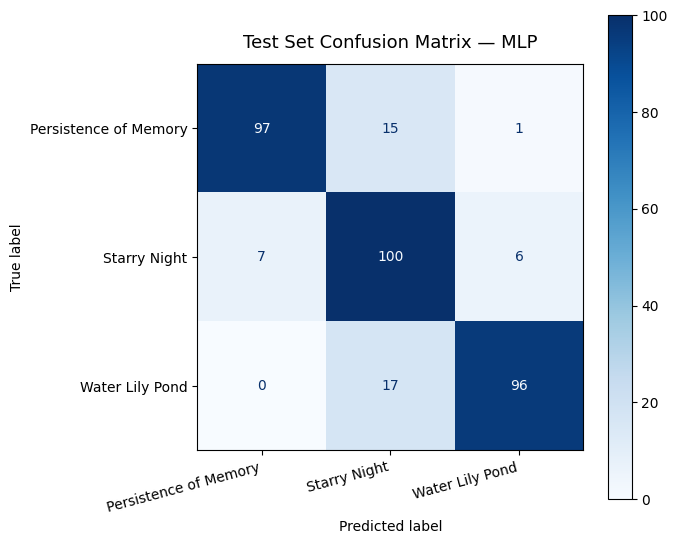


Confusion matrix saved to confusion_matrix.png


In [ ]:
train_preds = final_model.predict(X_train)
test_preds  = final_model.predict(X_test)
train_probs = final_model.predict_proba(X_train)
test_probs  = final_model.predict_proba(X_test)

train_acc  = accuracy_score(y_train, train_preds)
test_acc   = accuracy_score(y_test,  test_preds)
train_f1   = f1_score(y_train, train_preds, average="macro")
test_f1    = f1_score(y_test,  test_preds,  average="macro")
train_loss = log_loss(y_train, train_probs)
test_loss  = log_loss(y_test,  test_probs)

print("\n" + "=" * 40)
print("FINAL RESULTS")
print("=" * 40)
print(f"{'Metric':<20} {'Train':>8} {'Test':>8}")
print("-" * 40)
print(f"{'Accuracy':<20} {train_acc:>8.4f} {test_acc:>8.4f}")
print(f"{'Macro F1':<20} {train_f1:>8.4f} {test_f1:>8.4f}")
print(f"{'Log Loss':<20} {train_loss:>8.4f} {test_loss:>8.4f}")
print("=" * 40)

class_labels = ["Persistence of Memory", "Starry Night", "Water Lily Pond"]

cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, colorbar=True, cmap="Blues")
ax.set_title("Test Set Confusion Matrix — MLP", fontsize=13, pad=12)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("\nConfusion matrix saved to confusion_matrix.png")